# Modeling: CNN-GRU regressor for quentin_house

**Goal of this notebook:** train a model that maps each scenario's indoor temperature and heating power (480 minutes) to the six target indicators (HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf), and compare it with simple baselines.

What I take from `1_eda_clean.ipynb`:
- The 70/15/15 split and the normalization statistics (`Scalers`) were fitted there, on the training split only. This notebook only loads them.
- Two rules hold in every scenario, in **physical units**: HLC = HLC_mit + HLC_ext, and tau_n < tau_inf < tau_b (all targets positive). Z-scoring breaks them, so they are checked after converting predictions back to W/K and hours.
- The nearest-neighbour test showed that very similar inputs can have very different targets. So I do not expect a near-perfect model, and I compare the errors with that test.

**Models compared**
1. **Mean predictor:** always predicts the training mean. Any useful model must beat it.
2. **Baseline CNN:** a simple CNN (3 conv layers, then a fully connected layer), with no dT/dt input and no GRU.
3. **CNN-GRU, plain head:** the main architecture, with 6 free outputs.
4. **CNN-GRU, physics head:** same backbone, but the output layer builds the physics rules in.

**Plan**
1. Train the baseline CNN and both CNN-GRU models with the same settings.
2. Compare training curves, then test-set metrics per target.
3. Look at how predictions behave (predicted vs true), the physics rules, and errors by subset.

Numbers quoted in the text come from my run (seed 67). A re-run on the GPU can change them slightly in the last digit.

## 1. Setup


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from coenergy.data import load_splits
from coenergy.preprocessing import Scalers

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)

# This notebook lives in notebooks/, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'quentin_house'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR = PROJECT_ROOT / 'models'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_PATH = PROJECT_ROOT / 'data' / 'splits' / f'split_70_15_15_seed{SEED}.pt'
SCALER_PATH = PROJECT_ROOT / 'data' / 'splits' / f'scalers_seed{SEED}.pt'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

print(f'torch {torch.__version__} | device: {DEVICE}')


torch 2.11.0+cu128 | device: cuda


## 2. Load the normalized data

`Scalers` was fitted on the training split only, in the EDA. `load_splits` re-applies it to
every split and returns the normalized inputs and targets, reading the raw batches one at a
time so the raw dataset is never held in memory next to its normalized copy.


In [2]:
# Scalers fitted on the training split in the EDA notebook
scalers = Scalers.load(SCALER_PATH)
assert scalers.seed == SEED, 'Scalers were fitted on a different split'
print(f'Loaded scalers from {SCALER_PATH}')
print(f'temperature mean {scalers.temp_mean:.3f} | std {scalers.temp_std:.3f} | excitation scale {scalers.exc_scale:.0f} W')
print('targets:', scalers.target_labels)

Loaded scalers from c:\Users\Youssef\Desktop\coenergy-assessment\data\splits\scalers_seed67.pt
temperature mean 30.560 | std 4.788 | excitation scale 7000 W
targets: ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']


In [3]:
# Batches are read one at a time and written into preallocated split tensors,
# so the raw dataset is never held in memory next to its normalized copy.
data = load_splits(DATA_DIR, SPLIT_PATH, scalers)
train, val, test = data['train'], data['val'], data['test']

total_gb = sum(d.x.nbytes + d.y.nbytes for d in data.values()) / 1e9
for name, d in data.items():
    print(f'{name:5s} x {tuple(d.x.shape)} | y {tuple(d.y.shape)}')
print(f'Memory used by the normalized tensors: {total_gb:.2f} GB')

train x (700000, 2, 480) | y (700000, 6)
val   x (150000, 2, 480) | y (150000, 6)
test  x (150000, 2, 480) | y (150000, 6)
Memory used by the normalized tensors: 3.86 GB


In [4]:
# Sanity checks on the normalized data
for name, d in data.items():
    temp, exc = d.x[:, 0], d.x[:, 1]
    print(f'--- {name} ---')
    print(f'temperature  {temp.min():6.2f} to {temp.max():5.2f} | mean {temp.mean():+.3f} std {temp.std():.3f}')
    print(f'excitation   values {torch.unique(exc).tolist()}')
    for j, lbl in enumerate(scalers.target_labels):
        print(f'{lbl:8s}  {d.y[:, j].min():6.2f} to {d.y[:, j].max():5.2f} | mean {d.y[:, j].mean():+.3f} std {d.y[:, j].std():.3f}')

# The sum rule must still hold after converting back to physical units
phys = scalers.denorm_targets(val.y)
gap = (phys[:, 0] - phys[:, 1] - phys[:, 2]).abs().max().item()
print(f'\nval: max |HLC - (HLC_mit + HLC_ext)| = {gap:.2e} W/K')
del phys

--- train ---
temperature   -1.32 to  4.38 | mean +0.000 std 1.000
excitation   values [0.0, 1.0]
HLC        -3.88 to  4.31 | mean +0.000 std 1.000
HLC_mit    -2.96 to  4.16 | mean +0.000 std 1.000
HLC_ext    -3.25 to  4.29 | mean -0.000 std 1.000
tau_b      -2.95 to  7.14 | mean +0.000 std 1.000
tau_n      -2.92 to  7.37 | mean +0.000 std 1.000
tau_inf    -2.76 to  7.50 | mean -0.000 std 1.000
--- val ---
temperature   -1.32 to  3.96 | mean +0.003 std 1.001
excitation   values [0.0, 1.0]
HLC        -3.49 to  4.06 | mean +0.004 std 1.001
HLC_mit    -2.84 to  4.23 | mean +0.003 std 1.000
HLC_ext    -3.36 to  3.95 | mean +0.002 std 1.001
tau_b      -2.83 to  6.73 | mean -0.003 std 1.001
tau_n      -2.70 to  6.40 | mean -0.001 std 0.998
tau_inf    -2.50 to  7.26 | mean -0.002 std 1.000
--- test ---
temperature   -1.31 to  3.82 | mean +0.000 std 1.001
excitation   values [0.0, 1.0]
HLC        -3.31 to  3.96 | mean -0.000 std 1.001
HLC_mit    -2.71 to  4.21 | mean +0.002 std 1.001
HLC_ext  

**Observations**

The per-split statistics match the training split closely: on validation and test, every
column's mean stays within +/-0.004 and its standard deviation between 0.998 and 1.005 of the
training fit (0.0 / 1.0 exactly on train, by construction). The sum rule still holds after
denormalizing (max residual 3.05e-05 W/K on validation, float32 rounding) -- normalization does
not need to touch it, since it is enforced in physical units.


## 3. Model architecture

All models are in `src/coenergy/models.py` and return predictions in physical units (W/K and hours).

**Baseline CNN** (`BaselineCNN`): 3 blocks of convolution + ReLU + max-pooling (480 → 60 steps), then the features are flattened and passed to a fully connected layer. Flattening gives every time step its own weights, so the model has to learn the same pattern separately at each position where a heater switch can happen.

**CNN-GRU backbone** (`CNNGRU`), the main model:
- adds a third input channel, **dT/dt** (temperature change per minute, scaled to std 1 with `derivative_std` on the training split), because the speed of the temperature change carries the information about the building;
- 4 convolution blocks (conv + BatchNorm + GELU) detect local patterns and shorten the sequence from 480 to 60 steps;
- a 2-layer bidirectional GRU reads those 60 steps in order and keeps a memory of what happened before (heat stored in the walls);
- the mean over time plus the last step give a summary that does not depend on *when* the heater switched.

**Two output heads on the same backbone:**

| | Plain head | Physics head |
|---|---|---|
| Network outputs | 6 numbers, one per target | 5 numbers: HLC_mit, HLC_ext, tau_n and two gaps |
| HLC | predicted directly | computed as HLC_mit + HLC_ext |
| tau_inf, tau_b | predicted directly | tau_inf = tau_n + gap 1, tau_b = tau_inf + gap 2 |
| Positive values | not guaranteed | guaranteed (softplus is always > 0) |

**Why both?** The plain head shows what a standard network does on its own. The physics head shows whether building the rules into the model costs accuracy. Both use the same backbone and the same training settings, so any difference comes from the head only. The physics head's scales are set so that an untrained model predicts the training mean (`physics_head_scales`, using softplus(0) = ln 2).

In [4]:
from coenergy.models import build_baseline_cnn, build_cnn_gru, derivative_std

dT_std = derivative_std(train.x)
y_train_phys = scalers.denorm_targets(train.y)

torch.manual_seed(SEED)
model_baseline = build_baseline_cnn(scalers.tgt_mean, scalers.tgt_std)
model_plain = build_cnn_gru('plain', dT_std, scalers.tgt_mean, scalers.tgt_std)
model_physics = build_cnn_gru(
    'physics', dT_std, scalers.tgt_mean, scalers.tgt_std, y_train_phys=y_train_phys,
)

for name, model in [('baseline CNN', model_baseline), ('CNN-GRU plain', model_plain), ('CNN-GRU physics', model_physics)]:
    n_params = sum(p.numel() for p in model.parameters())
    print(f'{name:16s} | {n_params:,} parameters')

baseline CNN     | 505,494 parameters
CNN-GRU plain    | 246,214 parameters
CNN-GRU physics  | 246,085 parameters


## 4. Training configuration

`TrainConfig` (`src/coenergy/training.py`) is the same for every model, for a fair comparison:
- **Loss:** MSE on the z-scored targets, so HLC (std 31 W/K) and tau_n (std 2 h) weigh the same.
- **Optimizer:** AdamW (learning rate 2e-3, weight decay 1e-4) with a one-cycle schedule: the learning rate rises during the first 30% of training, then decreases to almost 0.
- **Batch size 256, 20 epochs.** Early stopping (patience 4) keeps the weights with the best validation loss.

These are standard values that worked in short test runs. They were not tuned systematically.

`RETRAIN = False` skips training and loads the saved checkpoints and histories instead (after a first full run).

In [5]:
from coenergy.training import TrainConfig, predict, train_model

cfg = TrainConfig(seed=SEED)
RETRAIN = True


def fit(model, name):
    # Train and save, or load the weights and history saved by a previous run
    ckpt, hist_path = CKPT_DIR / f'{name}.pt', CKPT_DIR / f'{name}_history.csv'
    if RETRAIN or not ckpt.exists() or not hist_path.exists():
        history = train_model(model, train, val, scalers, cfg, device=DEVICE, checkpoint_path=ckpt)
        history.to_csv(hist_path)
    else:
        model.load_state_dict(torch.load(ckpt, weights_only=False)['state_dict'])
        model.to(DEVICE)
        history = pd.read_csv(hist_path, index_col='epoch')
    return history


cfg

TrainConfig(epochs=20, batch_size=256, lr=0.002, weight_decay=0.0001, patience=4, eval_batch_size=4096, max_train=None, data_on_device=True, seed=67)

## 5. Baselines

A model score means little without something to compare it with.

**Mean predictor:** predicts the training mean for every scenario. By definition its R² is 0. Its MAE is the error you get when you ignore the inputs completely.

In [6]:
from coenergy.metrics import constraint_violations, per_target_metrics

y_test_phys = scalers.denorm_targets(test.y)
pred_mean = scalers.tgt_mean.expand(len(test), -1).clone()
per_target_metrics(pred_mean, y_test_phys, scalers.target_labels).round(3)

,MAE,RMSE,P95_abs,rel_MAE_%,R2
HLC,25.325001,31.349001,60.432999,11.172000,0.0
HLC_mit,21.434000,26.289000,49.658001,19.024000,-0.0
HLC_ext,13.827000,17.077999,32.907001,12.818000,-0.0
tau_b,7.963000,10.126000,19.420000,16.422001,-0.0
tau_n,1.583000,2.018000,3.867000,14.599000,-0.0
tau_inf,5.908000,7.559000,14.400000,19.742001,-0.0


**Baseline CNN:** trained with the same `cfg` as the CNN-GRU models. It is about 4 times faster per epoch (around 8 s against 37 s).

In [7]:
history_baseline = fit(model_baseline, 'baseline_cnn')
history_baseline.tail()

epoch  1 | train 0.8947 | val 0.8798 | R2 HLC 0.281 HLC_mit 0.226 HLC_ext 0.063 tau_b 0.010 tau_n 0.125 tau_inf 0.017 | 9s
epoch  2 | train 0.8799 | val 0.8771 | R2 HLC 0.282 HLC_mit 0.226 HLC_ext 0.074 tau_b 0.007 tau_n 0.130 tau_inf 0.018 | 8s
epoch  3 | train 0.8763 | val 0.8676 | R2 HLC 0.300 HLC_mit 0.231 HLC_ext 0.090 tau_b 0.019 tau_n 0.133 tau_inf 0.022 | 8s
epoch  4 | train 0.8715 | val 0.8620 | R2 HLC 0.305 HLC_mit 0.232 HLC_ext 0.106 tau_b 0.024 tau_n 0.137 tau_inf 0.024 | 8s
epoch  5 | train 0.8682 | val 0.8625 | R2 HLC 0.302 HLC_mit 0.232 HLC_ext 0.106 tau_b 0.025 tau_n 0.136 tau_inf 0.024 | 8s
epoch  6 | train 0.8649 | val 0.8580 | R2 HLC 0.311 HLC_mit 0.233 HLC_ext 0.115 tau_b 0.028 tau_n 0.139 tau_inf 0.027 | 8s
epoch  7 | train 0.8605 | val 0.8526 | R2 HLC 0.313 HLC_mit 0.233 HLC_ext 0.129 tau_b 0.033 tau_n 0.147 tau_inf 0.030 | 8s
epoch  8 | train 0.8563 | val 0.8513 | R2 HLC 0.317 HLC_mit 0.231 HLC_ext 0.141 tau_b 0.030 tau_n 0.147 tau_inf 0.027 | 8s
epoch  9 | train

,train_loss,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf,lr,time_s
epoch,,,,,,,,,,
16,0.817906,0.816529,0.356005,0.240668,0.217377,0.055787,0.183978,0.047230,3.764525e-04,7.885683
17,0.813280,0.811968,0.364790,0.243411,0.229231,0.056522,0.187010,0.047416,2.181245e-04,7.867351
18,0.809302,0.809493,0.366691,0.243942,0.234281,0.058521,0.190384,0.049406,9.900313e-05,7.877072
19,0.806540,0.808398,0.368034,0.244230,0.237144,0.059003,0.191653,0.049729,2.506173e-05,7.889813
20,0.805420,0.807905,0.368498,0.244268,0.238360,0.059419,0.192151,0.050053,8.003368e-09,7.899651


## 6. Train the CNN-GRU, plain head

The best weights (lowest validation loss) are saved to `models/cnn_gru_plain.pt` and loaded back into `model_plain` at the end.

In [9]:
history_plain = fit(model_plain, 'cnn_gru_plain')
history_plain.tail()

epoch  1 | train 0.8690 | val 0.8418 | R2 HLC 0.331 HLC_mit 0.231 HLC_ext 0.160 tau_b 0.032 tau_n 0.164 tau_inf 0.030 | 37s
epoch  2 | train 0.8223 | val 0.8325 | R2 HLC 0.343 HLC_mit 0.241 HLC_ext 0.226 tau_b 0.023 tau_n 0.152 tau_inf 0.021 | 37s
epoch  3 | train 0.7852 | val 0.7695 | R2 HLC 0.388 HLC_mit 0.252 HLC_ext 0.363 tau_b 0.090 tau_n 0.216 tau_inf 0.073 | 37s
epoch  4 | train 0.7691 | val 0.7764 | R2 HLC 0.383 HLC_mit 0.249 HLC_ext 0.382 tau_b 0.051 tau_n 0.223 tau_inf 0.052 | 37s
epoch  5 | train 0.7620 | val 0.8099 | R2 HLC 0.295 HLC_mit 0.201 HLC_ext 0.348 tau_b 0.032 tau_n 0.216 tau_inf 0.049 | 37s
epoch  6 | train 0.7556 | val 0.7608 | R2 HLC 0.401 HLC_mit 0.262 HLC_ext 0.384 tau_b 0.091 tau_n 0.224 tau_inf 0.074 | 37s
epoch  7 | train 0.7501 | val 0.7515 | R2 HLC 0.392 HLC_mit 0.262 HLC_ext 0.394 tau_b 0.113 tau_n 0.240 tau_inf 0.089 | 37s
epoch  8 | train 0.7457 | val 0.7443 | R2 HLC 0.406 HLC_mit 0.262 HLC_ext 0.420 tau_b 0.114 tau_n 0.240 tau_inf 0.091 | 37s
epoch  9

,train_loss,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf,lr,time_s
epoch,,,,,,,,,,
16,0.711351,0.721297,0.433647,0.277438,0.463577,0.133565,0.260667,0.103025,3.764525e-04,36.503569
17,0.706655,0.720155,0.434779,0.277759,0.466249,0.134761,0.261759,0.103460,2.181245e-04,36.478798
18,0.702586,0.719541,0.435732,0.278226,0.468451,0.134922,0.261792,0.103321,9.900313e-05,36.459506
19,0.699440,0.719183,0.435963,0.278013,0.469618,0.135239,0.262308,0.103452,2.506173e-05,36.456916
20,0.697920,0.719220,0.436278,0.278140,0.469893,0.135028,0.261890,0.103137,8.003368e-09,36.515629


## 7. Train the CNN-GRU, physics head

Same data, same `cfg`, only the head differs.

In [18]:
history_physics = fit(model_physics, 'cnn_gru_physics')
history_physics.tail()

epoch  1 | train 0.7060 | val 0.7199 | R2 HLC 0.435 HLC_mit 0.279 HLC_ext 0.466 tau_b 0.135 tau_n 0.261 tau_inf 0.104 | 37s
epoch  2 | train 0.7102 | val 0.7252 | R2 HLC 0.431 HLC_mit 0.277 HLC_ext 0.457 tau_b 0.128 tau_n 0.257 tau_inf 0.099 | 37s
epoch  3 | train 0.7185 | val 0.7319 | R2 HLC 0.423 HLC_mit 0.272 HLC_ext 0.446 tau_b 0.122 tau_n 0.251 tau_inf 0.095 | 36s
epoch  4 | train 0.7261 | val 0.7394 | R2 HLC 0.418 HLC_mit 0.272 HLC_ext 0.434 tau_b 0.107 tau_n 0.246 tau_inf 0.085 | 37s
epoch  5 | train 0.7297 | val 0.7508 | R2 HLC 0.409 HLC_mit 0.264 HLC_ext 0.432 tau_b 0.083 tau_n 0.240 tau_inf 0.067 | 37s
Early stopping: no improvement for 4 epochs


,train_loss,val_loss,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf,lr,time_s
epoch,,,,,,,,,,
1,0.706041,0.719888,0.435449,0.279079,0.466136,0.134870,0.261168,0.103664,0.000209,36.665271
2,0.710223,0.725187,0.430858,0.277180,0.457242,0.128236,0.256562,0.098517,0.000560,36.714109
3,0.718465,0.731933,0.422820,0.271506,0.445919,0.122151,0.250902,0.094842,0.001040,36.488159
4,0.726076,0.739386,0.418410,0.271978,0.433898,0.107265,0.246477,0.085441,0.001520,36.519536
5,0.729721,0.750846,0.409105,0.264447,0.432163,0.082519,0.239907,0.066596,0.001871,36.810962


## 8. Training curves

Train and validation loss (normalized MSE, where 1.0 = the mean predictor) for each model, then the validation R² of each target over the epochs.

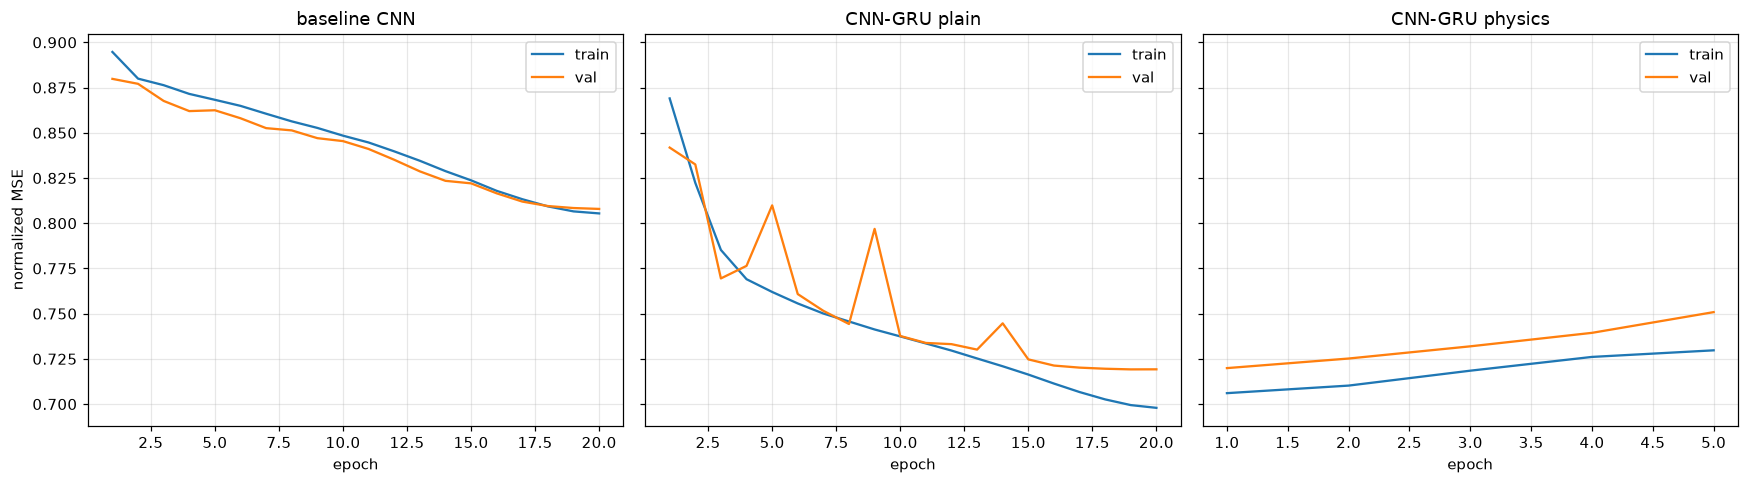

In [19]:
HISTORIES = [('baseline CNN', history_baseline), ('CNN-GRU plain', history_plain), ('CNN-GRU physics', history_physics)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, hist) in zip(axes, HISTORIES):
    ax.plot(hist.index, hist['train_loss'], label='train')
    ax.plot(hist.index, hist['val_loss'], label='val')
    ax.set_title(name)
    ax.set_xlabel('epoch')
    ax.legend()
axes[0].set_ylabel('normalized MSE')
fig.tight_layout()
fig.savefig(FIG_DIR / 'training_curves.png', dpi=150)
plt.show()

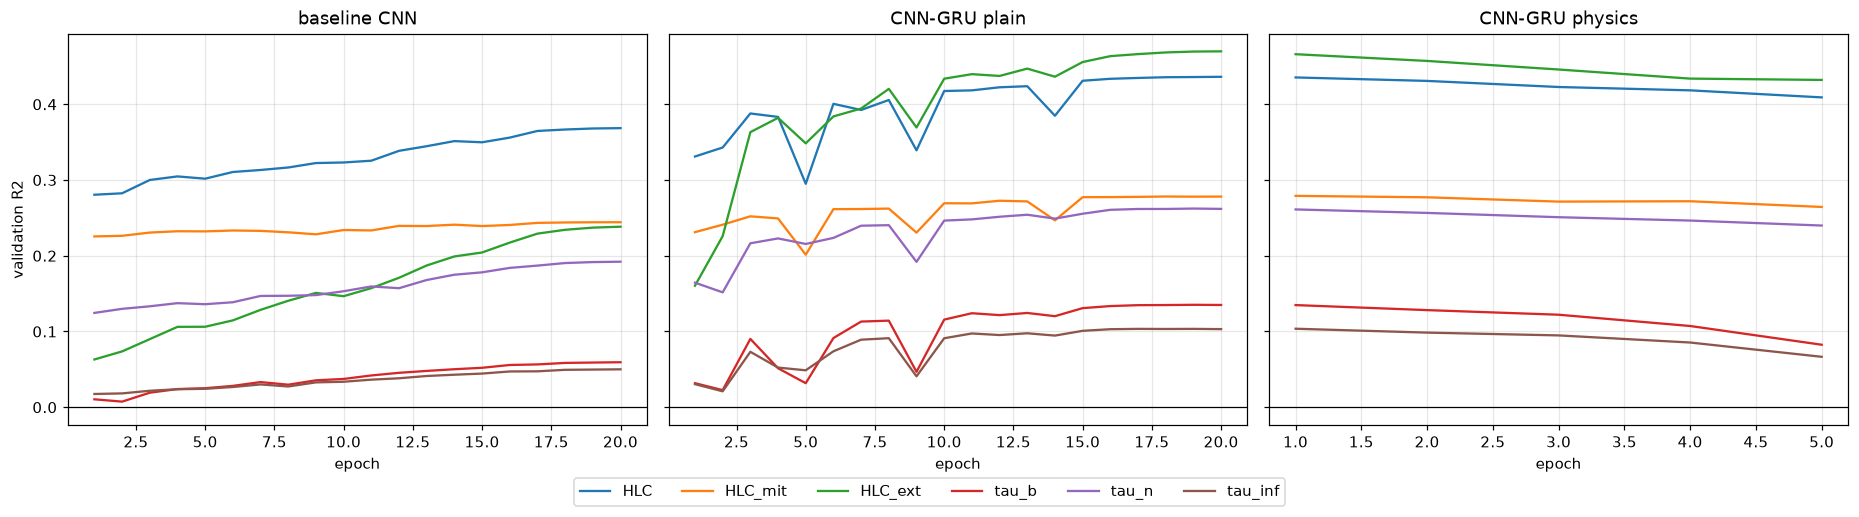

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (name, hist) in zip(axes, HISTORIES):
    for lbl in scalers.target_labels:
        ax.plot(hist.index, hist[f'R2_{lbl}'], label=lbl)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(name)
    ax.set_xlabel('epoch')
axes[0].set_ylabel('validation R2')
fig.legend(scalers.target_labels, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout()
fig.savefig(FIG_DIR / 'training_r2.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations (training curves)**
- **No overfitting.** For every model, train and validation loss stay close (CNN-GRU at epoch 20: about 0.70 train against 0.72 validation). A small gap only opens in the last epochs.
- **Training has settled for this schedule.** In the last epochs the learning rate is almost 0, so the loss barely moves (CNN-GRU validation loss 0.7206 → 0.7205 for the last two epochs). The baseline CNN is still improving slowly at epoch 20 (validation 0.8067 → 0.8063), but it is far behind.
- **The spike at epoch 9 appears in both CNN-GRU runs.** Both use the same seed, so they see the batches in the same order. At epoch 9 the learning rate is still high (the peak is at epoch 6, 30% of 20 epochs), and a few unlucky batches can disturb the weights and the BatchNorm statistics for one epoch. The next epoch recovers. It does not matter for the result, because the best weights are kept.
- **The plain and physics heads have almost the same curves.** Final validation loss 0.7206 (plain) and 0.7180 (physics). With only one run each, a difference this small is within noise.
- In the R² curves, the CNN-GRU learns HLC_ext and HLC best. For every model, tau_b and tau_inf are the worst targets.

## 9. Evaluation on the test set

`per_target_metrics` (`src/coenergy/metrics.py`) gives, for each target and in physical units:
- **MAE:** the average error (W/K or hours);
- **RMSE:** like MAE but large errors count more;
- **P95_abs:** 95% of the errors are smaller than this (the reference paper's metric);
- **rel_MAE_%:** MAE divided by the true value, to compare targets with different units;
- **R²:** 0 = no better than the mean predictor, 1 = perfect.

The test split is used once, here. The choice between models is based on validation (section 8).

In [21]:
preds = {
    'mean predictor': pred_mean,
    'baseline CNN': predict(model_baseline, test.x, cfg.eval_batch_size),
    'CNN-GRU plain': predict(model_plain, test.x, cfg.eval_batch_size),
    'CNN-GRU physics': predict(model_physics, test.x, cfg.eval_batch_size),
}
metrics = {name: per_target_metrics(p, y_test_phys, scalers.target_labels) for name, p in preds.items()}

print('Test R2')
display(pd.DataFrame({name: m['R2'] for name, m in metrics.items()}).round(3))
print('Test MAE (W/K for the HLC family, hours for tau)')
display(pd.DataFrame({name: m['MAE'] for name, m in metrics.items()}).round(2))

Test R2


,mean predictor,baseline CNN,CNN-GRU plain,CNN-GRU physics
HLC,0.0,0.366,0.435,0.433
HLC_mit,-0.0,0.242,0.278,0.278
HLC_ext,-0.0,0.240,0.470,0.467
tau_b,-0.0,0.060,0.135,0.135
tau_n,-0.0,0.196,0.265,0.263
tau_inf,-0.0,0.052,0.105,0.105


Test MAE (W/K for the HLC family, hours for tau)


,mean predictor,baseline CNN,CNN-GRU plain,CNN-GRU physics
HLC,25.33,19.940001,18.799999,18.840000
HLC_mit,21.43,18.430000,17.940001,17.950001
HLC_ext,13.83,11.930000,9.950000,9.980000
tau_b,7.96,7.710000,7.400000,7.410000
tau_n,1.58,1.420000,1.360000,1.360000
tau_inf,5.91,5.750000,5.590000,5.590000


In [22]:
# All metrics for the selected model
metrics['CNN-GRU physics'].round(3)

,MAE,RMSE,P95_abs,rel_MAE_%,R2
HLC,18.841,23.598,46.306000,8.250,0.433
HLC_mit,17.952,22.337,43.515999,15.771,0.278
HLC_ext,9.981,12.471,24.308001,9.144,0.467
tau_b,7.412,9.418,18.077000,15.213,0.135
tau_n,1.356,1.733,3.369000,12.330,0.263
tau_inf,5.594,7.149,13.691000,18.583,0.105


**Observations (test metrics)**

| Test R² | mean | baseline CNN | CNN-GRU plain | CNN-GRU physics |
|---|---|---|---|---|
| HLC | 0 | 0.37 | 0.43 | 0.44 |
| HLC_mit | 0 | 0.24 | 0.28 | 0.28 |
| HLC_ext | 0 | 0.24 | 0.47 | 0.47 |
| tau_b | 0 | 0.06 | 0.14 | 0.14 |
| tau_n | 0 | 0.20 | 0.26 | 0.27 |
| tau_inf | 0 | 0.05 | 0.11 | 0.11 |

- **Every model beats the mean predictor**, so the inputs do contain information. For HLC, the MAE goes from 25.3 W/K (mean) to 19.9 (baseline CNN) and 18.8 W/K (CNN-GRU).
- **The CNN-GRU beats the baseline CNN on every target.** The biggest gain is on HLC_ext (R² 0.24 → 0.47) and the time constants (tau_b doubles from 0.06 to 0.14). These depend on how fast the temperature changes, which is what the dT/dt channel and the GRU are meant to capture.
- **Plain and physics heads are tied** (differences of 0.001 to 0.003 in R²).
- **The scores are still modest.** The CNN-GRU explains 44% of the HLC variance and less than 15% for tau_b and tau_inf. HLC_ext (0.47) is much easier than HLC_mit (0.28), although both are parts of HLC. A possible explanation: the neighbouring spaces are probably at a temperature close to the indoor one, so heat lost to them leaves a weaker trace in the signal. This is a hypothesis, not something I tested.
- **Relative MAE looks better than it is.** 8.2% for HLC sounds good, but the mean predictor already gets 11.2%, because HLC values are large compared with their spread. R² and the comparison with the mean predictor are more honest.

### Comparison with the nearest-neighbour test (EDA, section 8)

In the EDA, pairs of scenarios with the same heating and temperature curves within 0.05 degC still had a median target gap close to that of random pairs. To compare this with the model, I convert both into an R²:
- For random pairs, the median gap is proportional to the target's standard deviation. For near-identical pairs, it is proportional to the error that remains when the inputs are known. So the test suggests a maximum R² of about **1 − (gap near-identical / gap random)²**.
- The values below are copied from the EDA table (switching group, curves within 0.05 degC, because 91% of the scenarios have a switching heating signal). This assumes roughly bell-shaped errors, so it is only an estimate, especially for the skewed tau targets.

In [23]:
# Median target gaps from the EDA nearest-neighbour test (switching group, curves within 0.05 degC)
ceiling = pd.DataFrame({
    'gap near-identical': [24.76, 22.84, 14.60, 8.85, 1.65, 6.60],
    'gap random pairs': [30.16, 25.48, 16.62, 9.22, 1.82, 6.75],
}, index=scalers.target_labels)
ceiling['R2 suggested by EDA test'] = 1 - (ceiling['gap near-identical'] / ceiling['gap random pairs']) ** 2
ceiling['R2 baseline CNN'] = metrics['baseline CNN']['R2']
ceiling['R2 CNN-GRU physics'] = metrics['CNN-GRU physics']['R2']
ceiling.round(3)

,gap near-identical,gap random pairs,R2 suggested by EDA test,R2 baseline CNN,R2 CNN-GRU physics
HLC,24.76,30.16,0.326,0.366,0.433
HLC_mit,22.84,25.48,0.196,0.242,0.278
HLC_ext,14.60,16.62,0.228,0.240,0.467
tau_b,8.85,9.22,0.079,0.060,0.135
tau_n,1.65,1.82,0.178,0.196,0.263
tau_inf,6.60,6.75,0.044,0.052,0.105


**Observations (comparison with the EDA test)**
- The EDA test suggests R² of about 0.33 for HLC, 0.20 for HLC_mit, 0.23 for HLC_ext, 0.18 for tau_n, and below 0.1 for tau_b and tau_inf.
- **The CNN-GRU does better than this on every target** (for example 0.44 against 0.33 for HLC, 0.47 against 0.23 for HLC_ext). So the EDA test is **too pessimistic**: its "near-identical" neighbours are close but not identical, and the model uses differences smaller than 0.05 degC.
- So I **cannot** claim that the model has reached the limit of the data. What the evidence does say: train and validation losses are equal and have levelled off, and very similar inputs still have very different targets. A bigger model will probably help only a little, but how much is left is unknown.
- The order of difficulty matches: tau_b and tau_inf are the hardest both in the EDA test and for the model.

## 10. Predicted vs true

A scatter plot of predictions against true values shows *how* the model is wrong. The dashed line is a perfect prediction; the red line is the average prediction for each bin of true values.

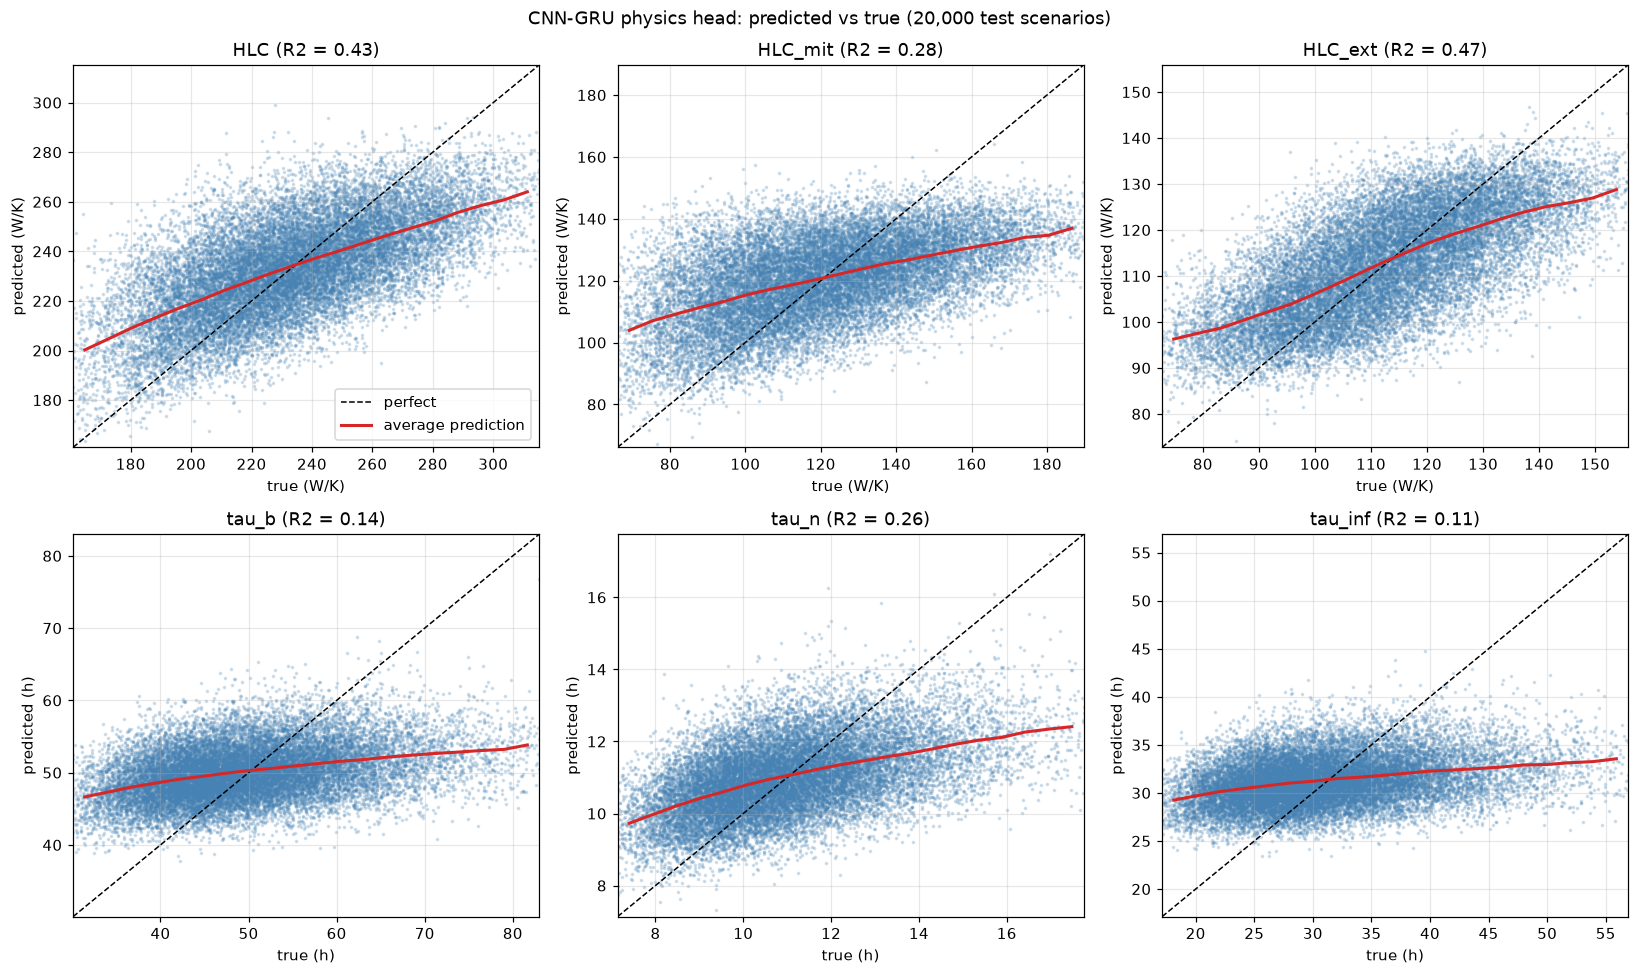

,slope,R2
HLC,0.427,0.433
HLC_mit,0.272,0.278
HLC_ext,0.466,0.467
tau_b,0.138,0.135
tau_n,0.268,0.263
tau_inf,0.110,0.105


In [24]:
pred_best = preds['CNN-GRU physics']
units = ['W/K'] * 3 + ['h'] * 3
sub = torch.randperm(len(test), generator=torch.Generator().manual_seed(SEED))[:20000]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, (ax, lbl) in enumerate(zip(axes.ravel(), scalers.target_labels)):
    t, p = y_test_phys[:, j], pred_best[:, j]
    ax.scatter(t[sub], p[sub], s=2, alpha=0.2, color='steelblue')
    lo, hi = t.quantile(0.005).item(), t.quantile(0.995).item()
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='perfect')
    edges = torch.linspace(lo, hi, 21)
    centers = (edges[:-1] + edges[1:]) / 2
    bin_mean = [p[(t >= a) & (t < b)].mean().item() for a, b in zip(edges[:-1], edges[1:])]
    ax.plot(centers, bin_mean, color='tab:red', lw=2, label='average prediction')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f'{lbl} (R2 = {metrics["CNN-GRU physics"].loc[lbl, "R2"]:.2f})')
    ax.set_xlabel(f'true ({units[j]})'); ax.set_ylabel(f'predicted ({units[j]})')
axes[0, 0].legend()
fig.suptitle('CNN-GRU physics head: predicted vs true (20,000 test scenarios)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'predicted_vs_true.png', dpi=150)
plt.show()

# Slope of the average prediction against the true value, next to R2
slope = [torch.cov(torch.stack([y_test_phys[:, j], pred_best[:, j]]))[0, 1].item() / y_test_phys[:, j].var().item()
         for j in range(6)]
pd.DataFrame({'slope': slope, 'R2': metrics['CNN-GRU physics']['R2']}, index=scalers.target_labels).round(3)

**Observations (predicted vs true)**
- The red line is much flatter than the dashed line: **predictions are pulled toward the mean.** High values are under-predicted and low values over-predicted.
- This is expected. When the model is unsure, the prediction with the smallest squared error is close to the average of all targets that look like this input, and that average is closer to the overall mean than the true value. The more uncertain the model, the flatter the line.
- The slope of that line is almost exactly the R² (HLC: slope 0.441, R² 0.436; tau_b: 0.144 and 0.137). That is what you get from a model that is uncertain but not biased.
- **Consequence:** the error grows the further a scenario is from the mean. A rough estimate is (1 − R²) × (distance from the mean). For scenarios with HLC above 300 W/K (true mean 311, 78 W/K above the overall mean), this gives 0.56 × 78 ≈ 44 W/K. The model under-predicts them by 46 W/K on average. The low tail behaves the same way: scenarios below 170 W/K are over-predicted by about 36 W/K.

## 11. Physics rules

`constraint_violations` gives the share of test predictions that break the sum rule (|HLC − HLC_mit − HLC_ext| > 1e-3 W/K), have a non-positive value, or get the tau order wrong. The next cell also shows **how large** the sum-rule gaps are, because the share alone does not say whether they matter.

In [25]:
violations = pd.DataFrame({name: constraint_violations(p) for name, p in preds.items() if name != 'mean predictor'})
display(violations)

for name in ['baseline CNN', 'CNN-GRU plain']:
    p = preds[name]
    gap = (p[:, 0] - p[:, 1] - p[:, 2]).abs()
    print(f'{name:14s} sum-rule gap: mean {gap.mean():.3f} | median {gap.median():.3f} | '
          f'P95 {gap.quantile(0.95):.3f} | max {gap.max():.3f} W/K')

,baseline CNN,CNN-GRU plain,CNN-GRU physics
sum_rule,0.964707,0.952627,0.0
non_positive,0.000000,0.000000,0.0
tau_order,0.000000,0.000000,0.0


baseline CNN   sum-rule gap: mean 0.022 | median 0.017 | P95 0.058 | max 0.318 W/K
CNN-GRU plain  sum-rule gap: mean 0.017 | median 0.012 | P95 0.046 | max 0.563 W/K


**Observations (physics rules)**
- The physics head breaks no rule, by construction.
- The plain head breaks the sum rule in about 95% of test scenarios, but the gaps are **tiny**: 0.016 W/K on average and 0.58 W/K at most, against an HLC error of 18.8 W/K. So it learned the sum rule almost perfectly from the data; it just never lands *exactly* on it.
- No model predicted a negative value or a wrong tau order on this test set.
- **So the physics head's advantage is a guarantee, not better accuracy.** On new data (another building, real measurements), nothing forces the plain head to keep the rules. The physics head always will, at no cost in accuracy here.

## 12. Error by subset

The EDA flagged three kinds of unusual scenarios (section 10): **hot** (indoor temperature above 45 degC), **high HLC** (above 300 W/K) and **constant heating** (the heater never switches). The same definitions are applied to the test split, using its own tensors: temperature and HLC are converted back to physical units, and constant heating is a heating channel with std 0.

In [26]:
temp_max_test = (test.x[:, 0] * scalers.temp_std + scalers.temp_mean).max(dim=1).values
flag_hot = temp_max_test > 45.0
flag_high_hlc = y_test_phys[:, 0] > 300.0
flag_const = test.x[:, 1].std(dim=1) == 0

print(f'test scenarios: {len(test):,}')
for name, mask in [('hot', flag_hot), ('high HLC', flag_high_hlc), ('constant heating', flag_const)]:
    print(f'{name:18s} {mask.sum().item():>7,} ({mask.float().mean():.2%})')


test scenarios: 150,000
hot                    119 (0.08%)
high HLC             2,808 (1.87%)
constant heating    13,978 (9.32%)


In [27]:
subsets = {
    'overall': torch.ones(len(test), dtype=torch.bool),
    'hot': flag_hot,
    'high HLC': flag_high_hlc,
    'constant heating': flag_const,
}
rows = []
for subset_name, mask in subsets.items():
    for name in ['baseline CNN', 'CNN-GRU physics']:
        mae = per_target_metrics(preds[name][mask], y_test_phys[mask], scalers.target_labels)['MAE']
        rows.append({'subset': subset_name, 'model': name, 'n': int(mask.sum()), **mae.to_dict()})
subset_mae = pd.DataFrame(rows).set_index(['subset', 'model'])
subset_mae.round(2)

n    HLC  HLC_mit  HLC_ext  tau_b  \
subset           model                                                     
overall          baseline CNN     150000  19.94    18.43    11.93   7.71   
                 CNN-GRU physics  150000  18.84    17.95     9.98   7.41   
hot              baseline CNN        119  12.26    10.56    10.61   8.35   
                 CNN-GRU physics     119  11.02    10.13     8.29   7.74   
high HLC         baseline CNN       2808  53.06    39.87    15.66  12.70   
                 CNN-GRU physics    2808  47.26    38.64    12.37  11.64   
constant heating baseline CNN      13978  22.66    20.08    10.69   7.31   
                 CNN-GRU physics   13978  20.98    18.94     9.75   7.15   

                                  tau_n  tau_inf  
subset           model                            
overall          baseline CNN      1.42     5.75  
                 CNN-GRU physics   1.36     5.59  
hot              baseline CNN      1.06     5.32  
                 CNN-GRU physics   0.93     4.99  
high HLC         baseline CNN      2.86     9.60  
                 CNN-GRU physics   2.55     8.86  
constant heating baseline CNN      1.40     5.50  
                 CNN-GRU physics   1.36     5.45

**Observations (subsets)**
- **High HLC:** the HLC MAE is about 46 W/K, against 18.8 W/K overall. This is the pull toward the mean from section 10, not a separate problem. Over-sampling these scenarios would only move the error to other scenarios.
- **Constant heating:** only slightly worse than overall (HLC MAE about 20.9 against 18.8 W/K). So the model gets most of its information from the passive temperature behaviour, and the heater switches add less than I expected. This links to the reference paper's main idea: how well a building can be identified depends on the heating signal applied to it.
- **Hot:** only 119 test scenarios, so these numbers are noisy. Their HLC error is lower (about 11 W/K). These are low-HLC buildings that were heated a lot, which might give more information, but the sample is too small to conclude.

## 13. Summary

**Results**
1. **The CNN-GRU is the best model.** On the test set it reaches R² 0.44 for HLC (MAE 18.8 W/K), 0.47 for HLC_ext, 0.28 for HLC_mit, 0.27 for tau_n, and only 0.14 and 0.11 for tau_b and tau_inf.
2. **It clearly beats both baselines.** The mean predictor has an HLC MAE of 25.3 W/K. The baseline CNN reaches R² 0.37 for HLC but only 0.24 for HLC_ext and 0.06 for tau_b. The dT/dt channel and the GRU help most on the targets that depend on how fast the temperature changes.
3. **The physics head costs nothing and gives guarantees.** Its accuracy is the same as the plain head's. The plain head already keeps the sum rule within 0.6 W/K, so the gain is not accuracy but the certainty that the rules always hold. I keep the physics head.
4. **Predictions are pulled toward the mean**, as expected for an uncertain model (slope of predicted vs true ≈ R²). This explains the large errors on the high-HLC (and low-HLC) tails.
5. **More capacity will probably help only a little.** Train and validation losses are equal and flat, and the EDA showed that very similar inputs have very different targets. But the model does better than the EDA test suggested, so I cannot say exactly how far the limit is.

**Limitations**
- One run per model: differences below about 0.01 in R² should not be interpreted.
- The training settings were not tuned.
- The test set contains the same heating schedules as training (only 2,798 distinct schedules), so the score measures new buildings with known schedules.

**Next steps**
1. Train 2 or 3 seeds of the physics head to get error bars, and average them. An average of physics-head predictions still respects all the rules.
2. Look at the error by heating pattern (number of switches, duty cycle) to measure how much the heater switches help.
3. Test on a split by heating schedule.
4. Ask coEnergy what varies between scenarios but is not in the inputs (outdoor and neighbouring temperatures, initial wall temperatures). This is probably what limits tau_b and tau_inf.